# Absolute P_L(p) with an anchored BAR ladder

Install `pip install '.[notebooks,matching,codes]'`. This tutorial follows the workflow curve's toric d=3 and d=5 bit-flip setting and ladder [0.30, 0.26, 0.22]. The MWPM decoder is fixed across all rungs; the failure set therefore stays fixed. The associated paper is in preparation.

In [1]:
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image, display
from mcmc4qec import spawn_seeds
QUICK = os.environ.get("MCMC4QEC_QUICK") == "1"
SEED = 2026
print(f"quick={QUICK}; root seed={SEED}")

quick=False; root seed=2026


At the first rung, independent direct Monte Carlo supplies an absolute anchor. BAR uses adjacent failure-conditioned ensembles to carry that probability down the ladder. An MC anchor must have **positive observed failures**; this notebook checks and reports the count. A coarser ladder can lose observed bidirectional support overlap and raise `OverlapError`. Add intermediate rungs or increase sampling when that happens.

In [2]:
from mcmc4qec import IndependentBitFlip, Problem, SamplingConfig, direct_mc, estimate_logical_error, OverlapError
from mcmc4qec.adapters import matching_from_check_matrix
from mcmc4qec.codes import make_toric_code
ladder = [0.30, 0.26, 0.22]
seeds = iter(spawn_seeds(SEED, 4))
curves = {}
for distance in (3, 5):
    code = make_toric_code(distance)
    decoder = matching_from_check_matrix(code.hz, logical_map=code.lz, identifier=f"toric-d{distance}-mwpm")
    problem = Problem(code.bit_flip_model(), IndependentBitFlip(code.n), decoder)
    anchor = direct_mc(problem, ladder[0], trials=200 if QUICK else 1500, seed=next(seeds))
    print(f"d={distance} anchor failures={anchor.failures}/{anchor.trials}")
    if anchor.failures == 0:
        raise RuntimeError("MC anchor observed no failure; increase its fixed trial count")
    try:
        bar = estimate_logical_error(problem, ladder, anchor=anchor,
            config=SamplingConfig(chains=4, samples=250 if QUICK else 1000,
                                  burn_in=80 if QUICK else 300),
            seed=next(seeds), bootstrap_replicates=0 if QUICK else 24)
    except OverlapError as exc:
        raise RuntimeError("Adjacent ladder rungs lack observed overlap; refine the ladder") from exc
    curves[distance] = (bar.estimates, bar.intervals)
    for rung, estimate, interval in zip(ladder, bar.estimates, bar.intervals):
        print(f"  p={rung:.2f} BAR P_L={estimate:.5f} interval={interval}")

d=3 anchor failures=1062/1500


  p=0.30 BAR P_L=0.70800 interval=(0.6853602074703797, 0.7313876623361794)
  p=0.26 BAR P_L=0.65397 interval=(0.6293624332562633, 0.6795457829952908)
  p=0.22 BAR P_L=0.58287 interval=(0.5557051593467333, 0.6113667179963084)


d=5 anchor failures=1104/1500


  p=0.30 BAR P_L=0.73600 interval=(0.7140275476497079, 0.758648600860073)
  p=0.26 BAR P_L=0.73017 interval=(0.6943030515118204, 0.7678941907616549)
  p=0.22 BAR P_L=0.72269 interval=(0.6652163444242656, 0.7851203993715207)


The first point inherits the MC anchor interval. Later intervals, when computed, assume adequate chain mixing and block length; they do not include an unmeasured mixing bias. `sample_faulty` frequencies alone are not absolute `P_L`. We keep the decoder fixed because a p-dependent BP-OSD decoder changes the failure set. The explicit `p_dependent_decoder_approx` mode omits that change from its interval.

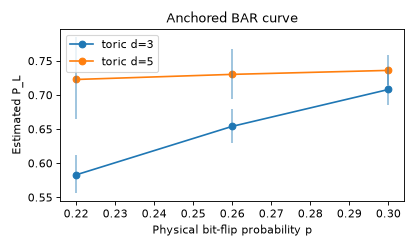

In [3]:
fig, ax = plt.subplots(figsize=(5.2, 3.1))
for distance, (estimates, intervals) in curves.items():
    ax.plot(ladder, estimates, marker="o", label=f"toric d={distance}")
    for p_rung, estimate, interval in zip(ladder, estimates, intervals):
        if interval is not None:
            ax.vlines(p_rung, interval[0], interval[1], alpha=.5)
ax.set(xlabel="Physical bit-flip probability p", ylabel="Estimated P_L", title="Anchored BAR curve")
ax.legend()
fig.tight_layout()
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=80)
display(Image(data=buffer.getvalue()))
plt.close(fig)